# Project 2 - Computational Engine Prototype

## Stochastic Asset Dynamics and Derivatives Pricing

This notebook implements the computational part of the project. It contains:

1. Simulation of a Geometric Brownian Motion (GBM) for a single asset.
2. Numerical verification of Itô's Lemma using the transformation $X_t = S_t^2$.
3. Simulation of an Ornstein-Uhlenbeck process using the Euler-Maruyama method.


# Part A - Single Asset Dynamics and Itô Verification

We assume that the asset price follows a Geometric Brownian Motion:

$$
dS_t = \mu S_t dt + \sigma S_t dW_t
$$

where:

- $S_0$ is the initial asset price;
- $\mu$ is the drift;
- $\sigma$ is the volatility;
- $W_t$ is a Brownian motion.

The exact solution of the GBM is:

$$
S_t = S_0 \exp\left[\left(\mu - \frac{1}{2}\sigma^2\right)t + \sigma W_t\right]
$$

Then we verify Itô's Lemma by considering the transformation:

$$
X_t = S_t^2
$$

By Itô's Lemma, the process $X_t$ satisfies:

$$
dX_t = (2\mu + \sigma^2)X_t dt + 2\sigma X_t dW_t
$$

The idea is to compare two methods:

1. Directly square the simulated GBM path: $X_t = S_t^2$.
2. Simulate the Itô-derived SDE for $X_t$.

If the two paths are close, this gives a numerical verification of Itô's Lemma.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # Fix the seed for reproducibility — same result every run

# --- Parameters ---
S0    = 100.0   # Initial asset price
mu    = 0.05    # Expected annual return (drift)
sigma = 0.20    # Annual volatility
T     = 1.0     # Investment horizon (years)
Steps = 252     # Approximate number of trading days per year
delta_t = T / Steps

time_steps = np.linspace(0, T, Steps)


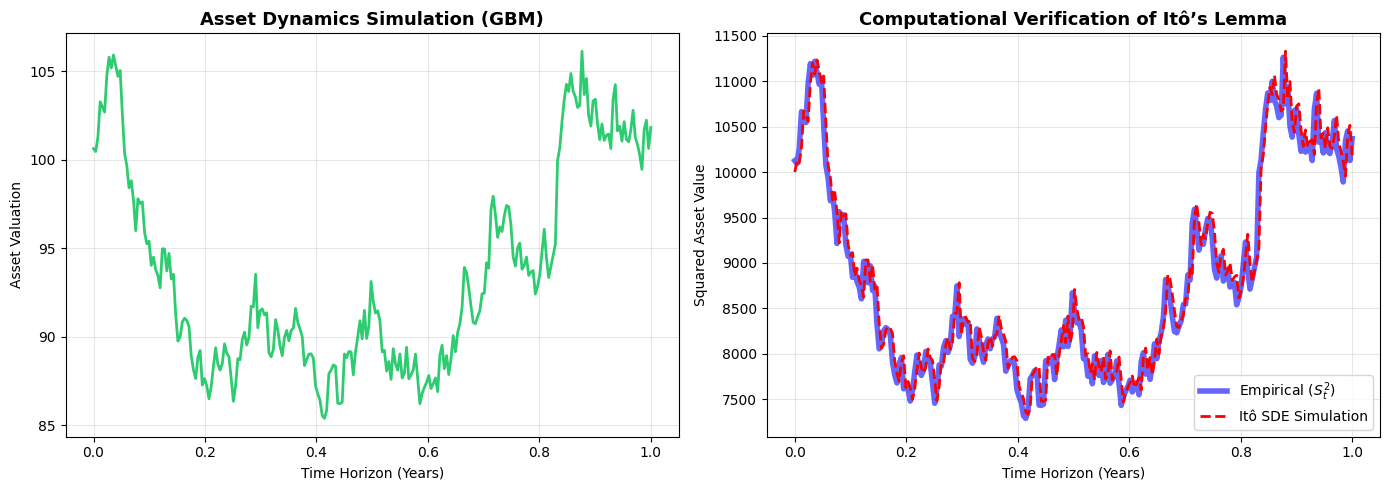

Maximum Deviation (Part A): 839.1341
Maximum Deviation between exact square and Itô SDE: 839.1341


In [2]:
# Generate standard normal shocks, scaled correctly for mathematical rigor
dW = np.random.normal(0, np.sqrt(delta_t), Steps)
W_t = np.cumsum(dW)

# ==========================================
# PART A.1: ASSET TRAJECTORY (GBM)
# ==========================================
# Using the exact closed-form solution for asset trajectory
S_t = S0 * np.exp(
    (mu - 0.5 * sigma**2) * time_steps +
    sigma * W_t
)

# ==========================================
# PART A.2: ITÔ VERIFICATION SDE (X_t = S_t^2)
# ==========================================
# 1. The empirical result (Directly squaring the exact solution)
X_t_direct = S_t**2

# 2. The theoretical result (Simulating the SDE derived via Itô's Lemma)
X_t_ito = np.zeros(Steps)
X_t_ito[0] = S0**2

# Euler-Maruyama step-by-step numerical solver
for t in range(1, Steps):
    # dX = (2*mu + sigma^2)*X*dt + (2*sigma)*X*dW
    drift = (2 * mu + sigma**2) * X_t_ito[t-1] * delta_t
    diffusion = (2 * sigma) * X_t_ito[t-1] * dW[t-1]
    X_t_ito[t] = X_t_ito[t-1] + drift + diffusion

# ==========================================
# VISUALIZATION SUITE (PROFESSIONAL DASHBOARD)
# ==========================================
plt.close('all') # Clear any ghost images

# Create a clean, wide figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Standard GBM ---
axes[0].plot(time_steps, S_t, color='#2ecc71', linewidth=2)
axes[0].set_title('Asset Dynamics Simulation (GBM)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Time Horizon (Years)')
axes[0].set_ylabel('Asset Valuation')
axes[0].grid(alpha=0.3)

# --- Plot 2: Itô's Lemma Verification ---
axes[1].plot(time_steps, X_t_direct, label='Empirical ($S_t^2$)', color='blue', alpha=0.6, linewidth=4)
axes[1].plot(time_steps, X_t_ito, label='Itô SDE Simulation', color='red', linestyle='--', linewidth=2)
axes[1].set_title('Computational Verification of Itô’s Lemma', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Time Horizon (Years)')
axes[1].set_ylabel('Squared Asset Value')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Auto-adjust spacing so everything looks perfect
plt.tight_layout()
plt.show()

# Verification Metric
max_deviation = np.max(np.abs(X_t_direct - X_t_ito))
print(f"Maximum Deviation (Part A): {max_deviation:.4f}")
print(f"Maximum Deviation between exact square and Itô SDE: {max_deviation:.4f}")


# Part B - Mean-Reverting Dynamics: Ornstein-Uhlenbeck Process

The Ornstein-Uhlenbeck process is used to model mean-reverting dynamics. Its stochastic differential equation is:

$$
dX_t = \kappa(\theta - X_t)dt + \sigma_{OU} dW_t
$$

where:

- $X_0$ is the initial value of the process;
- $\kappa$ is the speed of mean reversion;
- $\theta$ is the long-term equilibrium level;
- $\sigma_{OU}$ is the volatility of the OU process;
- $W_t$ is a Brownian motion.

The key idea is that the drift term $\kappa(\theta - X_t)$ pushes the process back toward $\theta$:

- if $X_t < \theta$, the drift is positive and pushes the process upward;
- if $X_t > \theta$, the drift is negative and pushes the process downward.

We simulate the process using the Euler-Maruyama method:

$$
X_{t+\Delta t} = X_t + \kappa(\theta - X_t)\Delta t + \sigma_{OU}\Delta W_t
$$


In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # Fix the seed for reproducibility

# ==========================================
# PART B: SYSTEM CONFIGURATION (OU PROCESS)
# ==========================================
# Time parameters (Ensuring standalone execution)
T = 1.0 # Time horizon (years)
Steps = 252 # Trading days per year
delta_t = T / Steps
time_steps = np.linspace(0, T, Steps)

# Process parameters (Using your specific configuration)
kappa = 0.8 # Speed of mean reversion
theta = 100.0 # Long-term equilibrium level
sigma_ou = 6.0 # Volatility coefficient
X0 = 92.0 # Initial valuation
n_paths = 10 # Generate 10 paths simultaneously for statistical visualization

sigma_inf  = sigma_ou / np.sqrt(2 * kappa)   # Stationary std dev
half_life  = np.log(2) / kappa               # Mean-reversion half-life (years)

print(f"Theoretical stationary std dev (σ_∞):  {sigma_inf:.4f}")
print(f"Mean-reversion half-life:               {half_life:.4f} years ({half_life*252:.1f} trading days)")


Theoretical stationary std dev (σ_∞):  4.7434
Mean-reversion half-life:               0.8664 years (218.3 trading days)


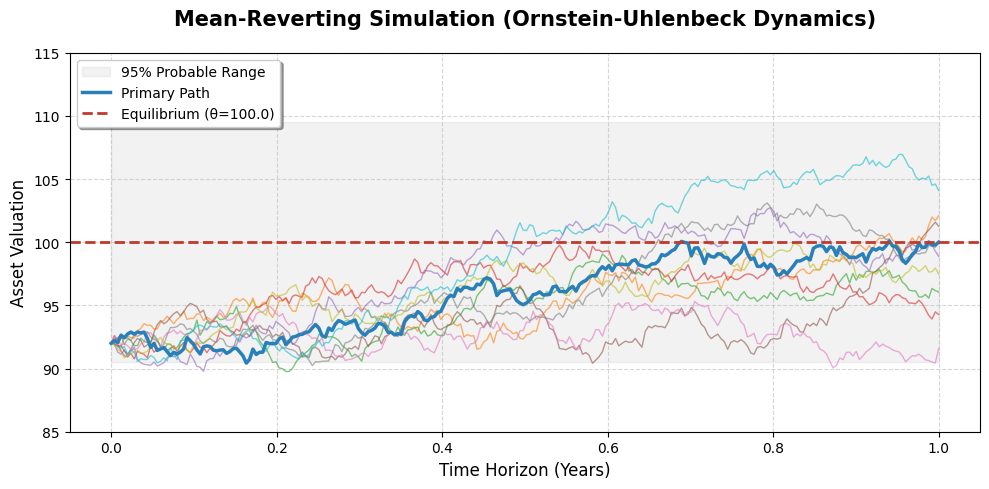


Empirical final mean: 98.5788  | Theoretical θ:   100.0
Empirical final std:  3.5970  | Theoretical σ_∞: 4.7434


In [4]:
# ==========================================
# IMPROVED SOLVER (Path-based Vectorization)
# ==========================================
# Initialize the array to hold all asset paths
paths = np.zeros((Steps, n_paths))
paths[0, :] = X0 # All paths start at X0

# ==========================================
# EULER-MARUYAMA NUMERICAL SOLVER
# ==========================================
# Professional Upgrade: Vectorized shock generation for computational speed
# Generate all random shocks at once for all steps and all paths
dW_all = np.random.normal(0, np.sqrt(delta_t), (Steps, n_paths))

for t in range(1, Steps):
    # dx = kappa * (theta - x) * dt + sigma * dW
    drift_component = kappa * (theta - paths[t-1, :]) * delta_t
    stochastic_component = sigma_ou * dW_all[t-1, :]

    paths[t, :] = paths[t-1, :] + drift_component + stochastic_component

# ==========================================
# PUBLICATION-READY VISUALIZATION
# ==========================================
plt.close('all') # Clear memory to prevent ghosting
plt.figure(figsize=(10, 5))

#Plotting the volatility corridor (theoretical limit).
#This enhances visualization by highlighting the process boundaries.
theoretical_std = sigma_ou / np.sqrt(2 * kappa)
plt.fill_between(time_steps, theta - 2*theoretical_std, theta + 2*theoretical_std,
color='gray', alpha=0.1, label='95% Probable Range')

# 2. Plotting a bundle of trajectories
plt.plot(time_steps, paths, linewidth=1, alpha=0.6)

# 3. Highlighting a single trajectory (in bold) for better tracking.
plt.plot(time_steps, paths[:, 0], color='#2980b9', linewidth=2.5, label='Primary Path')

# 4. Equilibrium level
plt.axhline(theta, color='#c0392b', linestyle='--', linewidth=2, label=f'Equilibrium (θ={theta})')

# Academic formatting
plt.title(f'Mean-Reverting Simulation (Ornstein-Uhlenbeck Dynamics)', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Time Horizon (Years)', fontsize=12)
plt.ylabel('Asset Valuation', fontsize=12)
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.ylim(theta - 15, theta + 15) # Centering the plot around the mean

plt.tight_layout()
plt.show()

# --- Quantitative Metrics: Empirical vs Theoretical ---
final_mean = paths[-1, :].mean()
final_std  = paths[-1, :].std()
print(f"\nEmpirical final mean: {final_mean:.4f}  | Theoretical θ:   {theta}")
print(f"Empirical final std:  {final_std:.4f}  | Theoretical σ_∞: {sigma_inf:.4f}")
